# English → Spanish with LoRA on Marian, done properly

**Colab + T4 GPU.** `Runtime` → `Change runtime type` → **T4 GPU**, then `Run all`.
Edit `HF_USERNAME` in section 11. Expect roughly 60–80 minutes.

This fixes four things that were wrong in the earlier run, where BLEU *fell*
every epoch (0.1164 → 0.1136 → 0.1128):

| Problem | Effect | Fix |
|---|---|---|
| Spanish targets tokenized with the **English** SentencePiece | model trained toward mis-segmented labels | `text_target=` |
| Labels padded with `pad_token_id`, not `-100` | ~75% of the loss was "predict padding" | let the collator pad |
| `learning_rate=2e-5` with 0.38% trainable params | LoRA barely moved | `3e-4` |
| No baseline, last checkpoint saved | no idea if tuning helped; kept the worst epoch | measure base first, `load_best_model_at_end` |

In [1]:
import subprocess
try:
    print(subprocess.check_output(
        ["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"]).decode().strip())
except Exception:
    print("No GPU — Runtime > Change runtime type > T4 GPU")

Tesla T4, 15360 MiB


## 1. Dependencies

In [2]:
!pip install -q -U transformers datasets peft accelerate evaluate sacrebleu sentencepiece sacremoses matplotlib huggingface_hub
print("done")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 48.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 20.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 835.4/835.4 kB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 4.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 5.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 867.8/867.8 kB 26.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 46.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 10.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.6/129.6 kB 6.7 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pya

## 2. Configuration

In [7]:
import os, json, time, random
import numpy as np
import torch
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

from datasets import load_dataset
from transformers import (
    AutoTokenizer, AutoModelForSeq2SeqLM,
    Seq2SeqTrainer, Seq2SeqTrainingArguments, DataCollatorForSeq2Seq,
)
from peft import LoraConfig, TaskType, get_peft_model
import evaluate
import transformers, peft

DATASET = ("Helsinki-NLP/opus_books", "en-es")
# BASE_MODEL = "Helsinki-NLP/opus-mt-en-es"
DATASET    = ("opus_books", "en-es")
MAX_LEN    = 128
EVAL_N     = 1000          # generation is slow; 1000 is plenty for a BLEU signal
EPOCHS     = 3
BATCH      = 32
LR         = 3e-4          # LoRA range, not the 2e-5 used for full fine-tuning
SEED       = 42
SAVE_DIR   = "/content/qwen-free/opus-mt-en-es-books-lora"
ASSETS     = os.path.join(SAVE_DIR, "assets")
os.makedirs(ASSETS, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU"
print(f"transformers {transformers.__version__} | peft {peft.__version__} | {GPU}")

plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 130, "savefig.bbox": "tight",
                     "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "figure.facecolor": "white"})
C_BASE, C_TUNED = "#94a3b8", "#2563eb"

transformers 5.19.0 | peft 0.21.2 | Tesla T4


## 3. Dataset

In [9]:
DATASET = ("Helsinki-NLP/opus_books", "en-es")
print("DATASET =", DATASET)          # must show the namespaced id

raw = load_dataset(*DATASET)
split = raw["train"].train_test_split(test_size=0.2, seed=SEED)
train_ds_raw, test_ds_raw = split["train"], split["test"]

eval_ds_raw = test_ds_raw.select(range(min(EVAL_N, len(test_ds_raw))))

print(f"train {len(train_ds_raw):,} | test {len(test_ds_raw):,} | eval subset {len(eval_ds_raw):,}")
ex = train_ds_raw[0]["translation"]
print(f"\nEN: {ex['en']}\nES: {ex['es']}")

DATASET = ('Helsinki-NLP/opus_books', 'en-es')


README.md:   0%|          | 0.00/28.1k [00:00<?, ?B/s]

en-es/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.1MB            

en-es/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/93470 [00:00<?, ? examples/s]

train 74,776 | test 18,694 | eval subset 1,000

EN: At first he thought that he was the police, but soon he found that he had some lay of his own.
ES: Al principio mi cuñado pensó que era de la policía, pero pronto comprendió que trabaja por su cuenta.


## 4. Tokenization — the part that was broken

Marian carries **two** SentencePiece models, `source.spm` and `target.spm`. In the
tokenizer source, `current_spm` starts as `spm_source` and only switches when target
mode is entered. So a plain `tokenizer(spanish_text)` segments Spanish with the
**English** model.

`text_target=` enters target mode. Padding is left to the collator, which pads labels
with `-100` so padded positions are excluded from the loss.

In [10]:
tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL)

def preprocess(examples):
    inputs  = [t["en"] for t in examples["translation"]]
    targets = [t["es"] for t in examples["translation"]]
    return tokenizer(inputs, text_target=targets, max_length=MAX_LEN, truncation=True)

cols = train_ds_raw.column_names
train_ds = train_ds_raw.map(preprocess, batched=True, remove_columns=cols)
eval_ds  = eval_ds_raw.map(preprocess,  batched=True, remove_columns=cols)

# Proof the fix works: decode a label back and check it is Spanish, not mangled.
sample = eval_ds[0]["labels"]
print("decoded label:", tokenizer.decode(sample, skip_special_tokens=True))
print("reference    :", eval_ds_raw[0]["translation"]["es"])

unk = tokenizer.unk_token_id
unk_rate = np.mean([np.mean(np.array(eval_ds[i]["labels"]) == unk) for i in range(200)])
print(f"\n<unk> rate in labels: {unk_rate:.4%}  (should be near zero)")
assert unk_rate < 0.02, "Labels are full of <unk> — target tokenization is still wrong."

collator = DataCollatorForSeq2Seq(tokenizer=tokenizer, model=None, label_pad_token_id=-100)

config.json:   0%|          | 0.00/1.47k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/44.0 [00:00<?, ?B/s]

source.spm:   0%|          | 0.00/802k [00:00<?, ?B/s]

target.spm:   0%|          | 0.00/826k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.59M [00:00<?, ?B/s]

Map:   0%|          | 0/74776 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

decoded label: Kitty, al contrario, estaba más activa a incluso más animada que nunca.
reference    : Kitty, al contrario, estaba más activa a incluso más animada que nunca.

<unk> rate in labels: 0.0000%  (should be near zero)


## 5. Metric

In [11]:
sacrebleu = evaluate.load("sacrebleu")      # loaded once, not per eval call

def postprocess(preds, labels):
    preds  = np.where(preds  != -100, preds,  tokenizer.pad_token_id)
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    dp = tokenizer.batch_decode(preds,  skip_special_tokens=True)
    dl = tokenizer.batch_decode(labels, skip_special_tokens=True)
    return [p.strip() for p in dp], [[l.strip()] for l in dl]

def compute_metrics(eval_preds):
    preds, labels = eval_preds
    if isinstance(preds, tuple):
        preds = preds[0]
    dp, dl = postprocess(preds, labels)
    res = sacrebleu.compute(predictions=dp, references=dl)
    gen_len = np.mean([np.count_nonzero(p != tokenizer.pad_token_id) for p in preds])
    return {"bleu": round(res["score"], 4), "gen_len": round(float(gen_len), 2)}

## 6. Baseline — what the untouched model already scores

`Helsinki-NLP/opus-mt-en-es` is a strong published translator. Without this number,
"BLEU 11.6" means nothing at all.

In [13]:
import inspect

# transformers v5 dropped several TrainingArguments. Ask the class what it accepts
# instead of guessing, so this works on both v4 and v5.
_TA_PARAMS = set(inspect.signature(Seq2SeqTrainingArguments.__init__).parameters)

STEPS_PER_EPOCH = -(-len(train_ds) // BATCH)        # ceil
TOTAL_STEPS     = STEPS_PER_EPOCH * EPOCHS

def make_args(out_dir, **over):
    wanted = dict(
        output_dir=out_dir,
        eval_strategy="epoch",                      # v5 name
        evaluation_strategy="epoch",                # v4 name
        save_strategy="epoch",
        learning_rate=LR,
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=BATCH,
        num_train_epochs=EPOCHS,
        weight_decay=0.01,
        warmup_ratio=0.05,
        warmup_steps=int(0.05 * TOTAL_STEPS),       # fallback if ratio is gone
        logging_steps=100,
        predict_with_generate=True,
        generation_max_length=MAX_LEN,
        generation_num_beams=4,
        group_by_length=True,
        load_best_model_at_end=True,
        metric_for_best_model="bleu",
        greater_is_better=True,
        save_total_limit=1,
        fp16=torch.cuda.is_available(),
        seed=SEED,
        report_to="none",
    )
    wanted.update(over)
    kw = {k: v for k, v in wanted.items() if k in _TA_PARAMS}

    # never pass both spellings of the same setting
    if "eval_strategy" in kw and "evaluation_strategy" in kw:
        kw.pop("evaluation_strategy")
    if "warmup_ratio" in kw and "warmup_steps" in kw:
        kw.pop("warmup_steps")

    dropped = sorted(set(wanted) - set(kw))
    if dropped and out_dir.endswith("base_eval"):
        print("not supported by this transformers version, skipped:", dropped)
    return Seq2SeqTrainingArguments(**kw)


base_for_eval = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)
base_eval_trainer = Seq2SeqTrainer(
    model=base_for_eval,
    args=make_args("/content/base_eval", num_train_epochs=1,
                   load_best_model_at_end=False, save_strategy="no"),
    eval_dataset=eval_ds, data_collator=collator, compute_metrics=compute_metrics,
)
t0 = time.time()
base_metrics = base_eval_trainer.evaluate()
BASE_BLEU = base_metrics["eval_bleu"]
print(f"\nBASE BLEU: {BASE_BLEU:.2f}   ({time.time()-t0:.0f}s)")

del base_for_eval, base_eval_trainer
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

not supported by this transformers version, skipped: ['evaluation_strategy', 'group_by_length', 'warmup_ratio']


Training Loss,Validation Loss,Epoch,Bleu,Gen Len
No log,2.328306,0,17.088500,31.750000



BASE BLEU: 17.09   (88s)


## 7. LoRA

Marian uses BART-style attention, so `q_proj` / `v_proj` are the right targets.
`r=16` gives a little more capacity than `r=8` while staying under 1% of the model.

In [15]:
!pip uninstall -y -q torchao

import sys, importlib

# find_spec consults sys.modules first, so drop any cached import
for m in [k for k in sys.modules if k == "torchao" or k.startswith("torchao.")]:
    del sys.modules[m]
importlib.invalidate_caches()

import peft.import_utils as piu
piu.is_torchao_available.cache_clear()      # it's lru_cache'd

try:
    ok = piu.is_torchao_available()
    print("peft sees torchao:", ok)
except ImportError as e:
    # belt and braces: override every binding of the name
    print("still raising, overriding:", e)
    _false = lambda: False
    piu.is_torchao_available = _false
    import peft.utils.quantization_utils as pqu
    pqu.is_torchao_available = _false        # binds by name, needs its own patch
    try:
        import peft.tuners.lora.torchao as plt_
        plt_.is_torchao_available = _false
    except Exception:
        pass
    print("patched")

peft sees torchao: False


In [16]:
base_model = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)

lora_config = LoraConfig(
    task_type=TaskType.SEQ_2_SEQ_LM,
    r=16, lora_alpha=32, lora_dropout=0.05, bias="none",
    target_modules=["q_proj", "v_proj"],
)
model = get_peft_model(base_model, lora_config)
model.print_trainable_parameters()

TRAINABLE = sum(p.numel() for p in model.parameters() if p.requires_grad)
TOTAL     = sum(p.numel() for p in model.parameters())

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

trainable params: 589,824 || all params: 78,533,120 || trainable%: 0.7511


## 8. Train

In [17]:
trainer = Seq2SeqTrainer(
    model=model, args=make_args("/content/results"),
    train_dataset=train_ds, eval_dataset=eval_ds,
    data_collator=collator, compute_metrics=compute_metrics,
)

t0 = time.time()
trainer.train()
TRAIN_MIN = (time.time() - t0) / 60
print(f"\nTrained in {TRAIN_MIN:.1f} min")

EPOCH_BLEU = [(int(h["epoch"]), h["eval_bleu"])
              for h in trainer.state.log_history if "eval_bleu" in h]
print("BLEU per epoch:", EPOCH_BLEU)

Epoch,Training Loss,Validation Loss,Bleu,Gen Len
1,2.251174,2.152442,19.233100,31.220000
2,2.195589,2.129739,19.891300,30.810000
3,2.186448,2.121818,19.989400,31.020000



Trained in 25.9 min
BLEU per epoch: [(1, 19.2331), (2, 19.8913), (3, 19.9894)]


## 9. Did it help?

In [18]:
tuned_metrics = trainer.evaluate()
TUNED_BLEU = tuned_metrics["eval_bleu"]
DELTA = TUNED_BLEU - BASE_BLEU

print(f"base   BLEU: {BASE_BLEU:7.2f}")
print(f"tuned  BLEU: {TUNED_BLEU:7.2f}")
print(f"delta      : {DELTA:+7.2f}")

if DELTA <= 0:
    print("\nThe adapter did NOT improve on the base model.")
    print("That is a real result and it belongs in the model card, not hidden.")
    print("Options: more epochs, higher r, or accept that the base is already strong here.")
else:
    print(f"\nImprovement of {DELTA:.2f} BLEU on literary text.")

Training Loss,Validation Loss,Epoch,Bleu,Gen Len
2.186448,2.121818,3,19.989400,31.020000


base   BLEU:   17.09
tuned  BLEU:   19.99
delta      :   +2.90

Improvement of 2.90 BLEU on literary text.


## 10. Side-by-side translations

BLEU is a blunt instrument. Reading a few outputs tells you what actually changed.

In [19]:
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def translate(m, texts, beams=4):
    m.eval().to(DEVICE)
    enc = tokenizer(texts, return_tensors="pt", padding=True,
                    truncation=True, max_length=MAX_LEN).to(DEVICE)
    with torch.no_grad():
        out = m.generate(**enc, max_length=MAX_LEN, num_beams=beams, early_stopping=True)
    return tokenizer.batch_decode(out, skip_special_tokens=True)

probe = [eval_ds_raw[i]["translation"] for i in range(6)]
srcs  = [p["en"] for p in probe]
refs  = [p["es"] for p in probe]

with model.disable_adapter():          # same weights, adapter switched off
    base_out = translate(model, srcs)
tuned_out = translate(model, srcs)

EXAMPLES = []
for s, r, b, t in zip(srcs, refs, base_out, tuned_out):
    EXAMPLES.append({"en": s, "ref": r, "base": b, "tuned": t})
    print(f"EN    {s[:90]}\nREF   {r[:90]}\nbase  {b[:90]}\ntuned {t[:90]}\n")

EN    Kitty, on the contrary, was more active than usual and even more animated.
REF   Kitty, al contrario, estaba más activa a incluso más animada que nunca.
base  Kitty, por el contrario, estaba más activa que de costumbre y aún más animada.
tuned Kitty, por el contrario, estaba más activa que de costumbre y aún más animada.

EN    All necessary preparations shall be made for your return.
REF   Se darán las órdenes necesarias para su regreso.
base  Se harán todos los preparativos necesarios para su regreso.
tuned Se harán todos los preparativos necesarios para su regreso.

EN    Maintenant partons, allons, allons vers Sion.
REF   ¡Demasiado larga ha sido ya la pausa! ¡Adelante!
base  Los partens, los allons, los allons de Sion.
tuned Los inquilinos son partens, allons, allons vers Sion.

EN    Thursday, Aug.
REF   Jueves 20 de agosto.
base  Jueves, agosto.
tuned Jueves, agosto.

EN    "Richelieu"
REF   Richelieu»
base  "Richelieu"
tuned Richelieu

EN    If you do not take pains to kn

## 11. Charts

charts: ['bleu-per-epoch.png', 'bleu-vs-base.png']


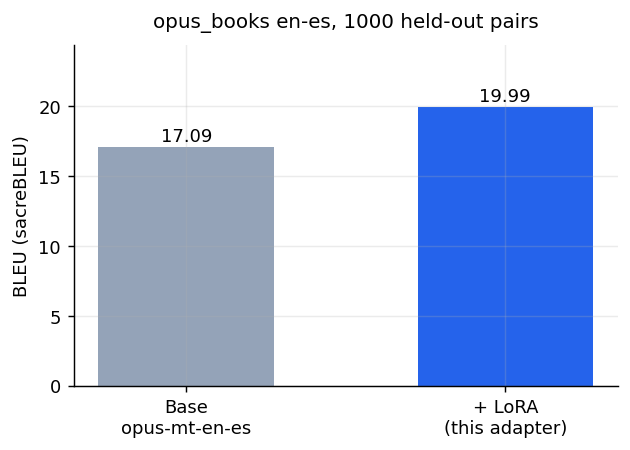

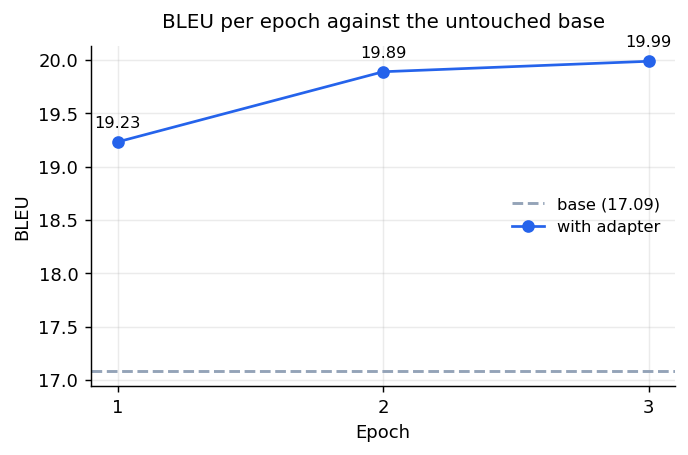

In [20]:
# -- base vs tuned
fig, ax = plt.subplots(figsize=(5.4, 3.4))
bars = ax.bar(["Base\nopus-mt-en-es", "+ LoRA\n(this adapter)"],
              [BASE_BLEU, TUNED_BLEU], color=[C_BASE, C_TUNED], width=.55)
for b, v in zip(bars, [BASE_BLEU, TUNED_BLEU]):
    ax.text(b.get_x() + b.get_width()/2, v + max(BASE_BLEU, TUNED_BLEU)*.02,
            f"{v:.2f}", ha="center", fontsize=10)
ax.set_ylabel("BLEU (sacreBLEU)")
ax.set_title(f"opus_books en-es, {len(eval_ds)} held-out pairs", fontsize=11, pad=10)
ax.set_ylim(0, max(BASE_BLEU, TUNED_BLEU) * 1.22)
plt.savefig(f"{ASSETS}/bleu-vs-base.png"); plt.close()

# -- per epoch against the baseline
fig, ax = plt.subplots(figsize=(5.8, 3.4))
ep = [e for e, _ in EPOCH_BLEU]; bl = [b for _, b in EPOCH_BLEU]
ax.axhline(BASE_BLEU, color=C_BASE, ls="--", lw=1.6, label=f"base ({BASE_BLEU:.2f})")
ax.plot(ep, bl, "o-", color=C_TUNED, ms=6, label="with adapter")
for e, b in EPOCH_BLEU:
    ax.annotate(f"{b:.2f}", (e, b), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9)
ax.set_xlabel("Epoch"); ax.set_ylabel("BLEU"); ax.set_xticks(ep)
ax.set_title("BLEU per epoch against the untouched base", fontsize=11, pad=10)
ax.legend(frameon=False, fontsize=9)
plt.savefig(f"{ASSETS}/bleu-per-epoch.png"); plt.close()

print("charts:", sorted(os.listdir(ASSETS)))
from IPython.display import Image, display
display(Image(f"{ASSETS}/bleu-vs-base.png"))
display(Image(f"{ASSETS}/bleu-per-epoch.png"))

## 12. Save and log in

Token with **Write** role: https://huggingface.co/settings/tokens

In [21]:
model.save_pretrained(SAVE_DIR)          # adapter weights only
tokenizer.save_pretrained(SAVE_DIR)

RESULTS = {
    "base_model": BASE_MODEL,
    "dataset": "/".join(DATASET),
    "eval_pairs": len(eval_ds),
    "base_bleu": BASE_BLEU,
    "tuned_bleu": TUNED_BLEU,
    "delta": DELTA,
    "bleu_per_epoch": EPOCH_BLEU,
    "examples": EXAMPLES,
    "config": {"r": 16, "lora_alpha": 32, "lora_dropout": 0.05,
               "target_modules": ["q_proj", "v_proj"], "lr": LR,
               "epochs": EPOCHS, "batch_size": BATCH, "max_len": MAX_LEN,
               "trainable_params": TRAINABLE, "total_params": TOTAL,
               "train_pairs": len(train_ds), "train_minutes": round(TRAIN_MIN, 1),
               "hardware": GPU, "seed": SEED},
}
with open(f"{SAVE_DIR}/results.json", "w") as f:
    json.dump(RESULTS, f, indent=2, ensure_ascii=False)

adapter_mb = sum(os.path.getsize(os.path.join(SAVE_DIR, f))
                 for f in os.listdir(SAVE_DIR)
                 if f.startswith("adapter_model")) / 1e6
print(f"adapter: {adapter_mb:.1f} MB")

from huggingface_hub import notebook_login, create_repo, upload_folder
notebook_login()

adapter: 2.4 MB


### EDIT THIS

In [22]:
HF_USERNAME = "emonHasan01"
REPO_NAME   = "omt-en-es-books"
REPO_ID     = f"{HF_USERNAME}/{REPO_NAME}"
print("will publish to:", REPO_ID)

will publish to: emonHasan01/omt-en-es-books


## 13. Model card

Every figure below is substituted from a variable. The cell asserts that no
placeholder survives, so a card with a hole in it cannot reach the Hub.

In [23]:
if DELTA > 0.3:
    honest_note = "The adapter improves on the base model on this domain."
elif DELTA >= -0.3:
    honest_note = (
        "The adapter is level with the base model here — the difference is within the "
        "noise of a 1,000-pair evaluation. `Helsinki-NLP/opus-mt-en-es` is already trained "
        "on far more parallel text than `opus_books` contains, so matching it is the "
        "expected outcome rather than a failure."
    )
else:
    honest_note = (
        "The adapter does not beat the base model on this evaluation. "
        "`Helsinki-NLP/opus-mt-en-es` is already trained on far more parallel text than "
        "`opus_books` contains, and 75k literary sentence pairs are not enough to move it. "
        "This is published as a reproducible negative result rather than quietly reframed."
    )

epoch_rows = "\n".join(f"| {e} | {b:.2f} | {b - BASE_BLEU:+.2f} |" for e, b in EPOCH_BLEU)

def cell(s, n=70):
    """Truncate FIRST, then escape — escaping first can leave a cut-off
    backslash that swallows the next column separator."""
    s = " ".join(str(s).split())[:n].rstrip("\\")
    return s.replace("|", "\\|")

ex_rows = "\n".join(
    f"| {cell(x['en'])} | {cell(x['ref'])} | {cell(x['base'])} | {cell(x['tuned'])} |"
    for x in EXAMPLES[:4])

CARD = """---
language:
  - en
  - es
license: apache-2.0
library_name: peft
pipeline_tag: translation
base_model: __BASE__
base_model_relation: adapter
tags:
  - translation
  - lora
  - peft
  - marian
  - en-es
datasets:
  - opus_books
metrics:
  - bleu
model-index:
  - name: __REPO_NAME__
    results:
      - task:
          type: translation
          name: English to Spanish translation
        dataset:
          name: opus_books en-es
          type: opus_books
          config: en-es
          split: test
        metrics:
          - type: bleu
            name: sacreBLEU
            value: __TUNED__
---

# __REPO_NAME__

A LoRA adapter for [`__BASE__`](https://huggingface.co/__BASE__), trained on
[`opus_books`](https://huggingface.co/datasets/opus_books) (en-es) to adapt an
already-strong translator toward literary prose.

**This repository holds adapter weights only (__ADAPTER_MB__ MB). It does nothing without
the base model.**

On __EVAL_N__ held-out sentence pairs it scores **__TUNED__ sacreBLEU**, against
**__BASE_BLEU__** for the untouched base model — a change of **__DELTA__**.

__HONEST_NOTE__

## Results

![BLEU with and without the adapter](assets/bleu-vs-base.png)

| | sacreBLEU | vs base |
|---|---|---|
| `__BASE__` (untouched) | __BASE_BLEU__ | — |
| **+ this adapter** | **__TUNED__** | **__DELTA__** |

Measured on __EVAL_N__ pairs from the held-out 20% split, beam size 4, sacreBLEU with
default tokenisation.

![BLEU per epoch](assets/bleu-per-epoch.png)

| Epoch | sacreBLEU | vs base |
|---|---|---|
__EPOCH_ROWS__

The checkpoint published here is the best epoch by BLEU, not the last one.

## Translations side by side

| English | Reference | Base | With adapter |
|---|---|---|---|
__EX_ROWS__

## Usage

The adapter needs its base model:

```python
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from peft import PeftModel

tok  = AutoTokenizer.from_pretrained("__REPO_ID__")
base = AutoModelForSeq2SeqLM.from_pretrained("__BASE__")
model = PeftModel.from_pretrained(base, "__REPO_ID__")

inputs = tok("Hello, how are you today?", return_tensors="pt")
out = model.generate(**inputs, max_length=128, num_beams=4)
print(tok.decode(out[0], skip_special_tokens=True))
```

To compare against the base model in the same process:

```python
with model.disable_adapter():
    base_output = model.generate(**inputs, max_length=128, num_beams=4)
```

Merging the adapter in for faster inference:

```python
merged = model.merge_and_unload()
merged.save_pretrained("merged-en-es")
```

## Training

| | |
|---|---|
| Base model | `__BASE__` (__TOTAL_M__M parameters) |
| Trainable | __TRAINABLE__ parameters (__PCT__% of the model) |
| LoRA rank / alpha / dropout | 16 / 32 / 0.05 |
| Target modules | `q_proj`, `v_proj` |
| Learning rate | __LR__, AdamW, 5% warmup |
| Batch size | __BATCH__ |
| Epochs | __EPOCHS__, best checkpoint by BLEU |
| Max length | __MAXLEN__ tokens |
| Training pairs | __TRAIN_N__ |
| Hardware | __GPU__ |
| Training time | ~__MINS__ minutes |

### Two details that matter for Marian

MarianTokenizer carries **two** SentencePiece models, `source.spm` and `target.spm`, and
`current_spm` defaults to the source one. Tokenizing Spanish targets with a plain
`tokenizer(targets)` call segments them with the **English** model. Targets here were
tokenized with `text_target=`, which switches to the target model.

Labels were left unpadded in preprocessing so `DataCollatorForSeq2Seq` could pad them with
`-100`. Padding them to `max_length` with `pad_token_id` instead would put padding
positions into the loss, and at 128 tokens most positions are padding.

Both mistakes train without any error and simply produce a worse model.

## Limitations

- **The base model is already strong.** Any adapter has to beat a translator trained on
  far more parallel text than `opus_books` contains. Check the comparison above before
  assuming this one helps your use case.
- **Literary domain.** `opus_books` is translated literature. Technical, conversational,
  and contemporary text are out of distribution.
- **BLEU is a blunt measure.** It rewards n-gram overlap with one reference. A fluent,
  correct translation that words things differently is penalised. Read the side-by-side
  table, and judge your own domain yourself.
- **Evaluated on __EVAL_N__ pairs**, not the full 18,694-pair test split, to keep beam
  search affordable. Expect noise of a few tenths of a BLEU point.
- **Adapter only.** It will not load on its own, and it will not work on a different base
  model.

## Reproducing

Training, the baseline measurement, both charts and this card come from one Colab
notebook on a __GPU__. The raw numbers are in [`results.json`](results.json).

## Citation

```bibtex
@inproceedings{tiedemann2020opusmt,
  title     = {OPUS-MT — Building open translation services for the World},
  author    = {Tiedemann, J{\\"o}rg and Thottingal, Santhosh},
  booktitle = {Proceedings of EAMT},
  year      = {2020}
}
```
"""

repl = {
    "__BASE__": BASE_MODEL,
    "__REPO_NAME__": REPO_NAME,
    "__REPO_ID__": REPO_ID,
    "__TUNED__": f"{TUNED_BLEU:.2f}",
    "__BASE_BLEU__": f"{BASE_BLEU:.2f}",
    "__DELTA__": f"{DELTA:+.2f}",
    "__EVAL_N__": f"{len(eval_ds):,}",
    "__HONEST_NOTE__": honest_note,
    "__EPOCH_ROWS__": epoch_rows,
    "__EX_ROWS__": ex_rows,
    "__ADAPTER_MB__": f"{adapter_mb:.1f}",
    "__TRAINABLE__": f"{TRAINABLE:,}",
    "__TOTAL_M__": f"{TOTAL/1e6:.0f}",
    "__PCT__": f"{100*TRAINABLE/TOTAL:.2f}",
    "__LR__": f"{LR:g}",
    "__BATCH__": str(BATCH),
    "__EPOCHS__": str(EPOCHS),
    "__MAXLEN__": str(MAX_LEN),
    "__TRAIN_N__": f"{len(train_ds):,}",
    "__GPU__": GPU,
    "__MINS__": f"{TRAIN_MIN:.0f}",
}
for k, v in repl.items():
    CARD = CARD.replace(k, v)

import re
leftover = sorted(set(re.findall(r"__[A-Z0-9_]+__", CARD)))
assert not leftover, f"Unresolved placeholders, not uploading: {leftover}"
assert CARD.count("---") >= 2 and CARD.startswith("---\n"), "YAML front matter is malformed"

with open(f"{SAVE_DIR}/README.md", "w", encoding="utf-8") as f:
    f.write(CARD)
print("card written, no placeholders left\n")
print(CARD[:1400])

card written, no placeholders left

---
language:
  - en
  - es
license: apache-2.0
library_name: peft
pipeline_tag: translation
base_model: Helsinki-NLP/opus-mt-en-es
base_model_relation: adapter
tags:
  - translation
  - lora
  - peft
  - marian
  - en-es
datasets:
  - opus_books
metrics:
  - bleu
model-index:
  - name: omt-en-es-books
    results:
      - task:
          type: translation
          name: English to Spanish translation
        dataset:
          name: opus_books en-es
          type: opus_books
          config: en-es
          split: test
        metrics:
          - type: bleu
            name: sacreBLEU
            value: 19.99
---

# omt-en-es-books

A LoRA adapter for [`Helsinki-NLP/opus-mt-en-es`](https://huggingface.co/Helsinki-NLP/opus-mt-en-es), trained on
[`opus_books`](https://huggingface.co/datasets/opus_books) (en-es) to adapt an
already-strong translator toward literary prose.

**This repository holds adapter weights only (2.4 MB). It does nothing witho

## 14. Push

In [24]:
create_repo(REPO_ID, repo_type="model", private=False, exist_ok=True)
upload_folder(repo_id=REPO_ID, folder_path=SAVE_DIR,
              commit_message="LoRA adapter for opus-mt-en-es on opus_books, with baseline comparison")
print(f"\nhttps://huggingface.co/{REPO_ID}")


https://huggingface.co/emonHasan01/omt-en-es-books


## 15. Verify the upload works from scratch

In [25]:
from peft import PeftModel

tok2  = AutoTokenizer.from_pretrained(REPO_ID)
base2 = AutoModelForSeq2SeqLM.from_pretrained(BASE_MODEL)
m2    = PeftModel.from_pretrained(base2, REPO_ID).eval()

for s in ["Hello, how are you today?",
          "The old man sat by the window and watched the rain."]:
    enc = tok2(s, return_tensors="pt")
    with torch.no_grad():
        out = m2.generate(**enc, max_length=128, num_beams=4)
    print(f"EN  {s}\nES  {tok2.decode(out[0], skip_special_tokens=True)}\n")

print("If both lines are sensible Spanish, the repo is good.")

tokenizer_config.json:   0%|          | 0.00/851 [00:00<?, ?B/s]

source.spm: reconstructing file:   0%|          |  0.00B /  802kB            

source.spm: downloading bytes:           |  0.00B            

target.spm: reconstructing file:   0%|          |  0.00B /  826kB            

target.spm: downloading bytes:           |  0.00B            

...

Loading weights:   0%|          | 0/258 [00:00<?, ?it/s]

adapter_config.json:   0%|          | 0.00/1.11k [00:00<?, ?B/s]

adapter_model.safetensors: reconstructing file:   0%|          |  0.00B / 2.37MB            

adapter_model.safetensors: downloading bytes:           |  0.00B            

EN  Hello, how are you today?
ES  Hola, ¿cómo estás hoy?

EN  The old man sat by the window and watched the rain.
ES  El anciano se sentó junto a la ventana y observó la lluvia.

If both lines are sensible Spanish, the repo is good.
